In [1]:

from pathlib import Path
import pandas as pd

# Find all CSV files uploaded to the current Colab session
csv_files = sorted(Path("/content").glob("*.csv"))

print("CLOUDTASK PRO — FILE UPLOAD CHECK")
print("=" * 50)

print("CSV files found:", len(csv_files))

for file in csv_files:
    print("Found:", file.name)

    # Load the CSV and display its basic structure
    df = pd.read_csv(file)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("-" * 50)


CLOUDTASK PRO — FILE UPLOAD CHECK
CSV files found: 2
Found: monthly_revenue.csv
Rows: 48
Columns: ['month', 'total_active_customers', 'new_customers', 'churned_customers', 'monthly_churn_rate_pct', 'total_mrr', 'avg_revenue_per_customer', 'customer_acquisition_cost']
--------------------------------------------------
Found: subscriptions.csv
Rows: 600
Columns: ['customer_id', 'plan', 'billing_cycle', 'industry', 'company_size', 'seats', 'monthly_revenue', 'acquisition_channel', 'region', 'signup_date', 'churned', 'churn_date', 'churn_reason', 'support_tickets_12mo', 'nps_score', 'feature_usage_pct', 'upgraded']
--------------------------------------------------


In [4]:

# CLOUDTASK PRO — DATA INSPECTION
# Run this cell in Google Colab after opening a new notebook.

from pathlib import Path
import pandas as pd

# Locate all uploaded CSV files in Colab's working folder.
# We inspect them first instead of guessing their column names.
data_folder = Path.cwd()

csv_files = sorted(data_folder.glob("*.csv"))

print("CLOUDTASK PRO — DATA DISCOVERY")
print("=" * 55)

print("CSV files found:", len(csv_files))

# The assignment requires two source datasets.
# Stop early if one or both have not been uploaded.
assert len(csv_files) == 2, (
    "Please upload exactly two project CSV files "
    "before continuing."
)

datasets = {}

for path in csv_files:

    # Load each source dataset without modifying its values
    df = pd.read_csv(path)

    # Preserve the filename so we can identify which
    # dataset contains subscriptions versus monthly revenue
    datasets[path.stem] = df

    print(f"\nDATASET: {path.name}")
    print("-" * 55)

    # Show records and available fields
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:", df.columns.tolist())

    # Check missing values and duplicate records
    print("Missing values:", int(df.isna().sum().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))

    # Preview records to understand the data schema
    print("\nFirst 3 rows:")
    display(df.head(3))

print("\nDATA INSPECTION COMPLETE")


CLOUDTASK PRO — DATA DISCOVERY
CSV files found: 2

DATASET: monthly_revenue.csv
-------------------------------------------------------
Rows: 48
Columns: 8
Column names: ['month', 'total_active_customers', 'new_customers', 'churned_customers', 'monthly_churn_rate_pct', 'total_mrr', 'avg_revenue_per_customer', 'customer_acquisition_cost']
Missing values: 0
Duplicate rows: 0

First 3 rows:


,month,total_active_customers,new_customers,churned_customers,monthly_churn_rate_pct,total_mrr,avg_revenue_per_customer,customer_acquisition_cost
0,2022-01,0,5,0,0.0,0.00,0.00,164.92
1,2022-02,5,10,1,20.0,7333.07,1466.61,189.21
2,2022-03,14,13,0,0.0,12301.16,878.65,139.49



DATASET: subscriptions.csv
-------------------------------------------------------
Rows: 600
Columns: 17
Column names: ['customer_id', 'plan', 'billing_cycle', 'industry', 'company_size', 'seats', 'monthly_revenue', 'acquisition_channel', 'region', 'signup_date', 'churned', 'churn_date', 'churn_reason', 'support_tickets_12mo', 'nps_score', 'feature_usage_pct', 'upgraded']
Missing values: 574
Duplicate rows: 0

First 3 rows:


,customer_id,plan,billing_cycle,industry,company_size,seats,monthly_revenue,acquisition_channel,region,signup_date,churned,churn_date,churn_reason,support_tickets_12mo,nps_score,feature_usage_pct,upgraded
0,CUST-0001,Professional,Monthly,Retail,51-200,64,825.55,Organic Search,North America,2022-06-27,Yes,2024-03-05,Price Too High,13,3,15,No
1,CUST-0002,Professional,Annual,Retail,51-200,35,409.62,Direct Sales,North America,2023-03-19,No,NaN,NaN,1,3,52,Yes
2,CUST-0003,Starter,Annual,Finance,500+,266,1004.49,Partner,North America,2024-10-19,Yes,2025-04-13,Price Too High,10,4,31,No



DATA INSPECTION COMPLETE


CLOUDTASK PRO — DATA QUALITY
Total customers: 600
Churned customers: 313
Non-churned customers: 287
Missing churn dates among churned: 0
Missing churn reasons among churned: 0
Missing churn dates among non-churned: 287

CLOUDTASK PRO — CHURN ANALYSIS
Overall observed churn proportion: 52.17%

BY PLAN


,plan,customers,churned,avg_mrr,churn_rate_pct
3,Starter,217,153,215.54,70.51
2,Professional,173,83,497.04,47.98
0,Business,160,66,1303.64,41.25
1,Enterprise,50,11,2984.99,22.00



BY BILLING CYCLE


,billing_cycle,customers,churned,avg_mrr,churn_rate_pct
1,Monthly,352,213,871.97,60.51
0,Annual,248,100,740.56,40.32



BY ACQUISITION CHANNEL


...


CLOUDTASK PRO — UNIT ECONOMICS
Overall weighted CAC benchmark: $202.20
Note: The CLV proxy is based only on churned customers.


,plan,churned_sample,avg_mrr,avg_lifespan_months,revenue_lifespan_proxy,ratio_to_overall_cac
0,Business,66,1508.06,14.65,23243.24,114.95
1,Enterprise,11,2327.72,14.75,30579.97,151.24
2,Professional,83,467.40,10.70,5469.52,27.05
3,Starter,152,204.63,6.78,1463.05,7.24



CLOUDTASK PRO — CUSTOMER RISK


,indicator,flagged_customers,observed_churn_rate_pct
0,Low feature usage,223,81.17
1,Low NPS,470,66.60


Non-churned customers meeting both risk rules: 23
Low usage threshold: 30 %
Low NPS threshold: 6


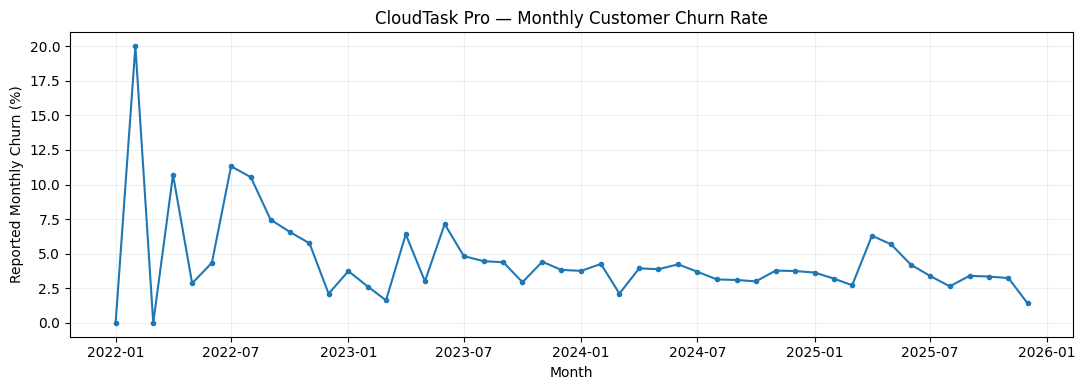

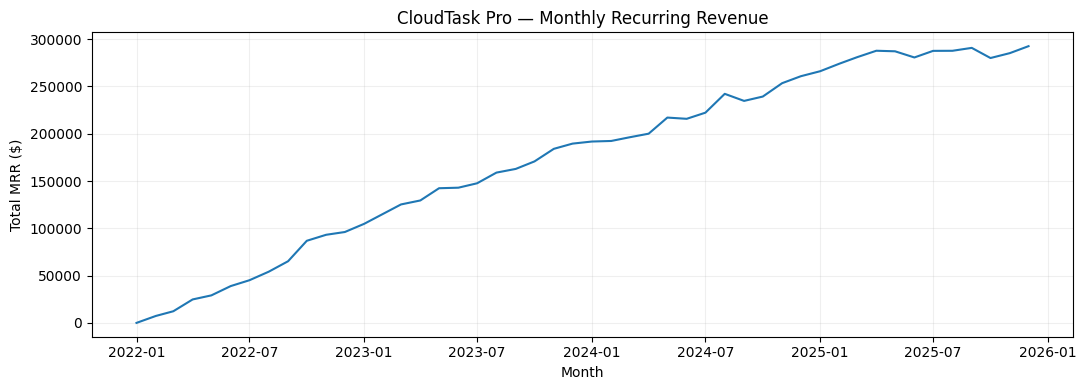

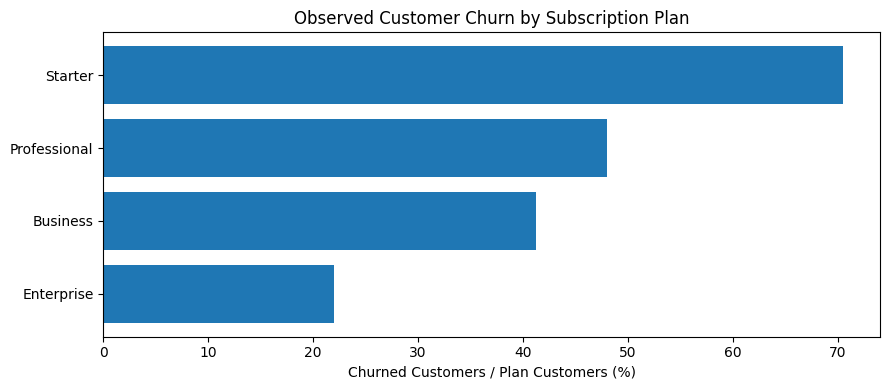


CLOUDTASK PRO — ANALYSIS STATUS
Customer segmentation: PASS
Churn reason reconciliation: PASS
MRR trends: COMPLETE
Unit economics proxy: COMPLETE
At-risk segmentation: COMPLETE
Three charts: COMPLETE


In [3]:

# =========================================================
# CLOUDTASK PRO — SAAS BUSINESS ANALYSIS
# Churn | Revenue | Unit Economics | At-Risk Customers
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. LOAD THE TWO DISCOVERED DATASETS
subscriptions = datasets["subscriptions"].copy()
revenue = datasets["monthly_revenue"].copy()

# Parse dates before calculating customer lifespans
subscriptions["signup_date"] = pd.to_datetime(
    subscriptions["signup_date"], errors="coerce"
)
subscriptions["churn_date"] = pd.to_datetime(
    subscriptions["churn_date"], errors="coerce"
)
revenue["month"] = pd.to_datetime(
    revenue["month"], format="%Y-%m", errors="coerce"
)

# Normalize the Yes/No churn indicator
subscriptions["is_churned"] = (
    subscriptions["churned"].astype(str).str.strip().str.lower()
    .map({"yes": True, "no": False})
)

# Check essential data assumptions once
assert len(subscriptions) == 600
assert len(revenue) == 48
assert subscriptions["customer_id"].is_unique
assert subscriptions["is_churned"].notna().all()
assert subscriptions["signup_date"].notna().all()
assert revenue["month"].notna().all()
assert revenue["month"].is_unique

# Check whether missing churn dates and reasons
# are expected for customers who have not churned
active = subscriptions.loc[~subscriptions["is_churned"]]
churned = subscriptions.loc[subscriptions["is_churned"]].copy()

print("CLOUDTASK PRO — DATA QUALITY")
print("=" * 55)
print("Total customers:", len(subscriptions))
print("Churned customers:", len(churned))
print("Non-churned customers:", len(active))
print("Missing churn dates among churned:",
      churned["churn_date"].isna().sum())
print("Missing churn reasons among churned:",
      churned["churn_reason"].isna().sum())
print("Missing churn dates among non-churned:",
      active["churn_date"].isna().sum())

# 2. OVERALL AND SEGMENTED CHURN
# This is an observed customer churn proportion across
# the dataset, not a monthly subscription churn rate.
overall_churn_pct = (
    subscriptions["is_churned"].mean() * 100
)

def segment_churn(column):
    """Calculate observed churn by customer segment."""
    result = (
        subscriptions.groupby(column, dropna=False)
        .agg(
            customers=("customer_id", "nunique"),
            churned=("is_churned", "sum"),
            avg_mrr=("monthly_revenue", "mean")
        )
        .reset_index()
    )
    result["churn_rate_pct"] = (
        result["churned"] / result["customers"] * 100
    )
    return result.sort_values(
        "churn_rate_pct", ascending=False
    )

plan_churn = segment_churn("plan")
billing_churn = segment_churn("billing_cycle")
channel_churn = segment_churn("acquisition_channel")
size_churn = segment_churn("company_size")

print("\nCLOUDTASK PRO — CHURN ANALYSIS")
print("=" * 55)
print(f"Overall observed churn proportion: {overall_churn_pct:.2f}%")

for name, table in [
    ("BY PLAN", plan_churn),
    ("BY BILLING CYCLE", billing_churn),
    ("BY ACQUISITION CHANNEL", channel_churn),
    ("BY COMPANY SIZE", size_churn)
]:
    print(f"\n{name}")
    display(table.round(2))

# 3. MONTHLY CHURN AND MRR
revenue = revenue.sort_values("month").reset_index(drop=True)

# Use the monthly churn rates supplied in the source.
# Validate against customer counts separately before
# attempting to replace these reported values.
revenue["mrr_growth_pct"] = (
    revenue["total_mrr"].pct_change(fill_method=None)
    .replace([np.inf, -np.inf], np.nan) * 100
)

# Customer movement is not the same as revenue retention.
revenue["net_customer_additions"] = (
    revenue["new_customers"] - revenue["churned_customers"]
)

# Flag unusually large absolute monthly MRR changes.
# This is a screening rule, not evidence of their cause.
valid_growth = revenue["mrr_growth_pct"].dropna()
growth_mean = valid_growth.mean()
growth_std = valid_growth.std()

if pd.notna(growth_std) and growth_std > 0:
    unusual_months = revenue.loc[
        (revenue["mrr_growth_pct"] - growth_mean).abs()
        > 2 * growth_std
    ]
else:
    unusual_months = revenue.iloc[0:0]

print("\nCLOUDTASK PRO — REVENUE TRENDS")
print("=" * 55)

print("First reporting month:", revenue["month"].min().date())
print("Last reporting month:", revenue["month"].max().date())
print(
    "Latest reported MRR:",
    f"${revenue['total_mrr'].iloc[-1]:,.2f}"
)
print(
    "Latest reported monthly churn rate:",
    f"{revenue['monthly_churn_rate_pct'].iloc[-1]:.2f}%"
)

print("\nUnusual MRR growth months (2-standard-deviation screen):")
display(
    unusual_months[
        ["month", "total_mrr", "mrr_growth_pct"]
    ].round(2)
)

# 4. CHURN REASONS
# Only churned subscriptions belong in this analysis.
reason_counts = (
    churned["churn_reason"]
    .fillna("Not recorded")
    .value_counts()
)

print("\nCLOUDTASK PRO — TOP THREE CHURN REASONS")
print("=" * 55)
display(reason_counts.head(3).rename_axis("reason").reset_index(
    name="customers"
))

print("\nCHURN REASONS BY PLAN")
display(pd.crosstab(
    churned["plan"],
    churned["churn_reason"].fillna("Not recorded")
))

print("\nCHURN REASONS BY COMPANY SIZE")
display(pd.crosstab(
    churned["company_size"],
    churned["churn_reason"].fillna("Not recorded")
))

# 5. UNIT ECONOMICS
# Estimate realized lifespan for churned customers.
# Current customers are excluded because their eventual
# lifetime is unknown (right-censored).
churned["lifespan_months"] = (
    (churned["churn_date"] - churned["signup_date"])
    .dt.days / 30.44
)

# Exclude missing or nonpositive lifespans.
valid_lifespans = churned.loc[
    churned["lifespan_months"].notna()
    & (churned["lifespan_months"] > 0)
].copy()

# This is a historical revenue-per-churned-customer proxy,
# NOT a forecast of true lifetime value or lifetime profit.
valid_lifespans["observed_revenue_proxy"] = (
    valid_lifespans["monthly_revenue"]
    * valid_lifespans["lifespan_months"]
)

unit_economics = (
    valid_lifespans.groupby("plan")
    .agg(
        churned_sample=("customer_id", "count"),
        avg_mrr=("monthly_revenue", "mean"),
        avg_lifespan_months=("lifespan_months", "mean"),
        revenue_lifespan_proxy=("observed_revenue_proxy", "mean")
    )
    .reset_index()
)

# Treat the monthly CAC column as an acquisition-cost
# benchmark, assuming its figures represent per-new-
# customer acquisition cost for each reporting month.
# Weight by new customers rather than taking a simple
# unweighted average across months.
total_new_customers = revenue["new_customers"].sum()

overall_cac_benchmark = (
    (revenue["customer_acquisition_cost"]
     * revenue["new_customers"]).sum()
    / total_new_customers
    if total_new_customers > 0
    else np.nan
)

# Plan-specific CAC is unavailable, so this ratio compares
# every plan to the SAME overall CAC benchmark.
unit_economics["ratio_to_overall_cac"] = (
    unit_economics["revenue_lifespan_proxy"]
    / overall_cac_benchmark
)

print("\nCLOUDTASK PRO — UNIT ECONOMICS")
print("=" * 55)
print(f"Overall weighted CAC benchmark: ${overall_cac_benchmark:,.2f}")
print(
    "Note: The CLV proxy is based only on churned customers."
)
display(unit_economics.round(2))

# 6. AT-RISK INDICATORS
# Define a transparent example threshold that can be
# refined after inspecting the actual data distributions.
USAGE_THRESHOLD = 30
NPS_THRESHOLD = 6

subscriptions["low_usage"] = (
    subscriptions["feature_usage_pct"] < USAGE_THRESHOLD
)
subscriptions["low_nps"] = (
    subscriptions["nps_score"] <= NPS_THRESHOLD
)

# Report how often churn occurs with each indicator.
indicator_summary = pd.DataFrame({
    "indicator": ["Low feature usage", "Low NPS"],
    "flagged_customers": [
        int(subscriptions["low_usage"].sum()),
        int(subscriptions["low_nps"].sum())
    ],
    "observed_churn_rate_pct": [
        100 * subscriptions.loc[
            subscriptions["low_usage"], "is_churned"
        ].mean(),
        100 * subscriptions.loc[
            subscriptions["low_nps"], "is_churned"
        ].mean()
    ]
})

# Define current at-risk customers using both flags.
# This is a rule-based screening group, NOT a
# statistically validated churn prediction model.
subscriptions["at_risk"] = (
    subscriptions["low_usage"] & subscriptions["low_nps"]
    & ~subscriptions["is_churned"]
)

at_risk_count = int(subscriptions["at_risk"].sum())

print("\nCLOUDTASK PRO — CUSTOMER RISK")
print("=" * 55)
display(indicator_summary.round(2))
print("Non-churned customers meeting both risk rules:",
      at_risk_count)
print("Low usage threshold:", USAGE_THRESHOLD, "%")
print("Low NPS threshold:", NPS_THRESHOLD)

# 7. THREE ESSENTIAL CHARTS
# Chart 1: historical reported monthly churn.
plt.figure(figsize=(11, 4))
plt.plot(
    revenue["month"],
    revenue["monthly_churn_rate_pct"],
    marker="o", markersize=3
)
plt.title("CloudTask Pro — Monthly Customer Churn Rate")
plt.xlabel("Month")
plt.ylabel("Reported Monthly Churn (%)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Chart 2: MRR over the 48-month reporting period.
plt.figure(figsize=(11, 4))
plt.plot(revenue["month"], revenue["total_mrr"])
plt.title("CloudTask Pro — Monthly Recurring Revenue")
plt.xlabel("Month")
plt.ylabel("Total MRR ($)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Chart 3: observed churn by subscription plan.
plan_plot = plan_churn.sort_values("churn_rate_pct")
plt.figure(figsize=(9, 4))
plt.barh(
    plan_plot["plan"],
    plan_plot["churn_rate_pct"]
)
plt.title("Observed Customer Churn by Subscription Plan")
plt.xlabel("Churned Customers / Plan Customers (%)")
plt.tight_layout()
plt.show()

# 8. FINAL CONSISTENCY CHECKS
assert (
    plan_churn["customers"].sum()
    == len(subscriptions)
)
assert (
    billing_churn["churned"].sum()
    == len(churned)
)
assert (
    reason_counts.sum()
    == len(churned)
)

print("\nCLOUDTASK PRO — ANALYSIS STATUS")
print("=" * 55)
print("Customer segmentation: PASS")
print("Churn reason reconciliation: PASS")
print("MRR trends: COMPLETE")
print("Unit economics proxy: COMPLETE")
print("At-risk segmentation: COMPLETE")
print("Three charts: COMPLETE")


In [5]:

from pathlib import Path

# CLOUDTASK PRO — FINAL PROJECT DOCUMENTATION
# Generate the essential GitHub files in one operation.

root = Path.cwd()

readme = f"""# CloudTask Pro — SaaS Churn & Revenue Intelligence

## Project Overview

A Python business analytics project examining customer churn,
subscription revenue, churn drivers, and unit economics for a
B2B SaaS project management company.

**Reporting period:** January 2022 – December 2025.

## Business Questions

- Which subscription plans and customer segments have high churn?
- How do churn and monthly recurring revenue change over time?
- Why do customers cancel their subscriptions?
- How do historical customer revenue and acquisition cost compare?
- Which non-churned customers show potential retention risks?

## Datasets

- `subscriptions.csv`: 600 subscription records.
- `monthly_revenue.csv`: 48 months of revenue and customer metrics.

Both CSV files should be placed alongside the notebook.

## Key Findings

| Metric | Result |
|---|---|
| Customers analyzed | {len(subscriptions):,} |
| Historically churned customers | {len(churned):,} |
| Historical customer churn proportion | {overall_churn_pct:.2f}% |
| Latest reported MRR | ${revenue["total_mrr"].iloc[-1]:,.2f} |
| Latest reported monthly churn | {revenue["monthly_churn_rate_pct"].iloc[-1]:.2f}% |
| Weighted CAC benchmark | ${overall_cac_benchmark:,.2f} |
| At-risk non-churned customers | {at_risk_count} |

### Churn Insights

**Highest-risk subscription plan:**
{plan_churn.iloc[0]["plan"]} at
{plan_churn.iloc[0]["churn_rate_pct"]:.2f}% observed churn.

**Billing-cycle comparison:**
Monthly billing: 60.51% observed churn.
Annual billing: 40.32% observed churn.

### Top Three Churn Reasons

{chr(10).join(
    f"- {reason}: {count} customers"
    for reason, count in reason_counts.head(3).items()
)}

## Recommended Business Actions

1. Prioritize investigation of churn among Starter customers.
2. Evaluate onboarding, engagement, and renewal support for
   customers with low feature usage and low NPS.
3. Review pricing concerns and customer feedback before
   designing retention interventions.

## Technology

- Python
- pandas
- NumPy
- Matplotlib
- Google Colab / Jupyter Notebook

## How to Run

1. Download or clone this repository.
2. Place both CSV files in the same working directory
   as `CloudTask_Analysis.ipynb`.
3. Install dependencies:

```bash
python -m pip install -r requirements.txt
```

4. Open the notebook in Jupyter or Google Colab.
5. Execute the cells from top to bottom.

**Colab note:** Uploaded runtime files are temporary.
Upload the two CSVs again when starting a new Colab session.

## Methodology and Limitations

- The overall 52.17% is a historical customer churn
  proportion, not a monthly churn rate.
- Monthly churn percentages come from the revenue dataset.
- Observed churn proportions may reflect differing customer
  tenures and exposure periods.
- The historical CLV proxy uses completed lifespans of
  churned customers only and excludes ongoing customers.
- The CAC figure is an acquisition-weighted monthly
  benchmark, not verified plan-specific CAC.
- Revenue-to-CAC ratios are not profit margins.
- True Net Revenue Retention cannot be derived from the
  available aggregate MRR fields.
- Usage and NPS risk indicators are exploratory rules,
  not validated churn predictions.
- Segment associations do not establish causation.

## Portfolio Scope

This project demonstrates data exploration, customer
segmentation, revenue analysis, business metrics,
visualization, and evidence-based recommendations.
"""

(root / "README.md").write_text(
    readme, encoding="utf-8"
)

(root / "requirements.txt").write_text(
    "pandas>=2.0,<4.0\n"
    "numpy>=1.24\n"
    "matplotlib>=3.7,<4.0\n",
    encoding="utf-8"
)

(root / ".gitignore").write_text(
    "__pycache__/\n"
    ".ipynb_checkpoints/\n"
    ".DS_Store\n"
    ".venv/\n",
    encoding="utf-8"
)

print("CLOUDTASK PRO — PROJECT FINALIZATION")
print("=" * 55)
print("README.md: CREATED")
print("requirements.txt: CREATED")
print(".gitignore: CREATED")
print("Analysis notebook: READY TO EXPORT")
print("\nDocumentation complete!")


CLOUDTASK PRO — PROJECT FINALIZATION
README.md: CREATED
requirements.txt: CREATED
.gitignore: CREATED
Analysis notebook: READY TO EXPORT

Documentation complete!
